In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

PIXEL_MAX = 255.0

x_train = x_train / PIXEL_MAX
x_test = x_test / PIXEL_MAX

TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test = x_test.reshape((x_test.shape[0], TIME_STEPS, FEATURES))

NUM_CLASSES = 10

y_train = to_categorical(y_train, NUM_CLASSES)
y_test = to_categorical(y_test, NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
prepared: (60000, 28, 28) (60000, 10)


In [3]:
model = models.Sequential()

LSTM_UNITS = 128

model.add(layers.LSTM(
    LSTM_UNITS,
    activation='relu',
    input_shape=(28, 28)
))

OUT_UNITS = 10

model.add(layers.Dense(
    OUT_UNITS,
    activation='softmax'
))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

test_loss, test_acc = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 46s 48ms/step - accuracy: 0.8186 - loss: 0.5540 - val_accuracy: 0.9427 - val_loss: 0.1764
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 44s 47ms/step - accuracy: 0.9575 - loss: 0.1396 - val_accuracy: 0.9706 - val_loss: 0.1021
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9710 - loss: 0.0942 - val_accuracy: 0.9762 - val_loss: 0.0813
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.9771 - loss: 0.0731 - val_accuracy: 0.9788 - val_loss: 0.0688
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 44ms/step - accuracy: 0.9812 - loss: 0.0611 - val_accuracy: 0.9809 - val_loss: 0.0682
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 45ms/step - accuracy: 0.9835 - loss: 0.0528 - val_accuracy: 0.9868 - val_loss: 0.0493
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9854 - loss: 0.0461 - val_accuracy: 0.9842 - val_loss: 0.0518
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 45ms/step - accuracy: 0.9878 - loss: 0.0399 - 

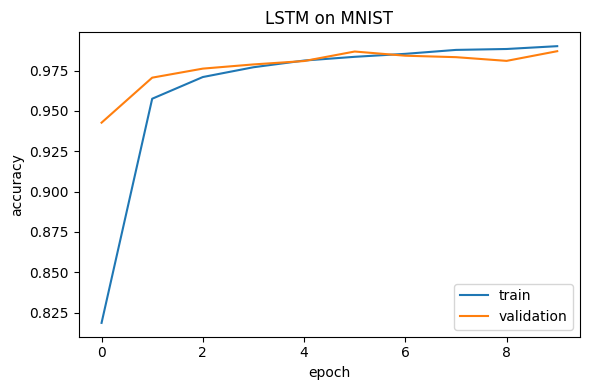

In [5]:
plt.figure(figsize=(6,4))

plt.plot(history.history['accuracy'], label='train')

plt.plot(history.history['val_accuracy'], label='validation')

plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.title('LSTM on MNIST')

plt.tight_layout()
plt.show()

1. Why do we feed the image as (28, 28) instead of flattening it to a 784-vector as in an MLP?

We use (28, 28) because LSTM is designed to process sequential data. Each image is treated as a sequence of 28 rows, with each row containing 28 pixel values. This helps the model learn relationships between rows. Flattening into 784 values removes the sequence structure.

2. What is the role of hidden state hₜ versus cell state Cₜ in the LSTM?
- Hidden state (hₜ): Stores the current output information of the LSTM at each time step.
- Cell state (Cₜ): Stores long-term information and carries it across time steps.
Both help LSTM remember important information while processing sequences.

3. The final Dense layer uses softmax. Why softmax and not sigmoid here?

Softmax is used because MNIST has 10 mutually exclusive classes (digits 0–9). It converts the outputs into probabilities that sum to 1. Sigmoid produces independent probabilities and is mainly used for binary or multi-label classification.

4. If you changed LSTM(128) to LSTM(32), what would you expect to happen to accuracy and parameter count? Why?

The parameter count decreases because the number of LSTM units is reduced from 128 to 32. Training becomes faster and requires less memory. However, accuracy may decrease because the model has less capacity to learn complex patterns.

5. Replace activation='relu' with the default 'tanh'. Does the accuracy change? Which is recommended, and why?

The accuracy may change slightly depending on training. The default tanh activation is recommended for LSTM because it is the standard activation used in its internal computations and supports efficient cuDNN GPU execution when the required conditions are satisfied.

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245,024 (957.13 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 163,350 (638.09 KB)